In [ ]:
# Install optional CLV package
!pip install lifetimes -q

import pandas as pd
import numpy as np
import zipfile
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve, mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 13.6 MB/s eta 0:00:00


# Data Cleaning & Preprocessing stage:

In [ ]:
zip_path = "/content/Telco Customer Churn Dataset.zip"
extract_path = "/content/telco_churn_data"

# Extract ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Find CSV file inside extracted folder
csv_files = [
    os.path.join(root, file)
    for root, dirs, files in os.walk(extract_path)
    for file in files
    if file.endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError("No CSV file found inside the ZIP file.")

csv_path = csv_files[0]

# Load dataset
df = pd.read_csv(csv_path)

# Replace blank strings with NaN
df.replace(" ", np.nan, inplace=True)

# Convert numeric-looking columns
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="ignore")

# 1. Handle missing values
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 2. Remove duplicate records
df.drop_duplicates(inplace=True)

# 3. Standardize customer IDs
if "customerID" in df.columns:
    df["customerID"] = df["customerID"].astype(str).str.strip().str.upper()

# 4. Correct invalid transactions / invalid values
invalid_numeric_cols = ["TotalCharges", "MonthlyCharges", "tenure"]

for col in invalid_numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].fillna(df[col].median())
        df.loc[df[col] < 0, col] = df[col].median()

# 5. Detect and treat outliers using IQR method
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_limit, lower_limit, df[col])
    df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])

# 6. Convert date columns into datetime format
date_columns = ["SignupDate", "ContractStartDate", "ContractEndDate"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Save cleaned data
output_path = "/content/Cleaned_Telco_Customer_Churn.csv"
df.to_csv(output_path, index=False)

print("Data cleaning completed successfully.")
print("CSV file used:", csv_path)
print("Cleaned file saved at:", output_path)
print(df.info())
print(df.head())

Data cleaning completed successfully.
CSV file used: /content/telco_churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv
Cleaned file saved at: /content/Cleaned_Telco_Customer_Churn.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   float64
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   float64
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  St

#Exploratory Data Analysis:

In [ ]:
# Load cleaned dataset
df = pd.read_csv("/content/Cleaned_Telco_Customer_Churn.csv")

# Basic overview
print("Dataset Shape:", df.shape)
print("\nColumn Info:")
print(df.info())

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

# Convert date columns if available
date_columns = ["SignupDate", "ContractStartDate", "ContractEndDate"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

Dataset Shape: (7043, 21)

Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   float64
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   float64
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pa

## Feature Engineering Rationale

Feature engineering is a critical step to transform raw data into a format that is more suitable for machine learning models. The features selected here are designed to capture key aspects of customer behavior and engagement in the telecommunications domain, which are known to be strong indicators for churn and customer lifetime value:

*   **Recency, Frequency, Monetary Value (RFM)**: These are classic customer segmentation metrics. 'Recency' measures how recently a customer engaged, 'Frequency' measures how often, and 'Monetary Value' measures how much they spent. In a subscription-based business like telco, these are adapted to `Customer_Tenure` (as a proxy for frequency and recency) and `TotalCharges` (for monetary value).
*   **Customer_Tenure**: Directly measures the loyalty and duration of a customer's relationship, often inversely correlated with churn.
*   **Monthly_Spending**: Represents the recurring value generated by the customer.
*   **Average_Order_Value/Average_Purchase_Value**: Gives insights into the average transaction size, reflecting customer buying power or service tier.
*   **Total_Transactions/Purchase_Frequency**: Measures the number of distinct engagements, important for understanding activity levels.
*   **Days_Since_Last_Purchase/Recency**: Indicates recent activity, crucial for identifying active vs. dormant customers.
*   **Product_Diversity**: Captures the breadth of services a customer uses, potentially indicating 'stickiness' to the provider.
*   **Engagement_Frequency**: Combines tenure and product diversity to give a more nuanced view of how actively a customer utilizes services relative to their time with the company.

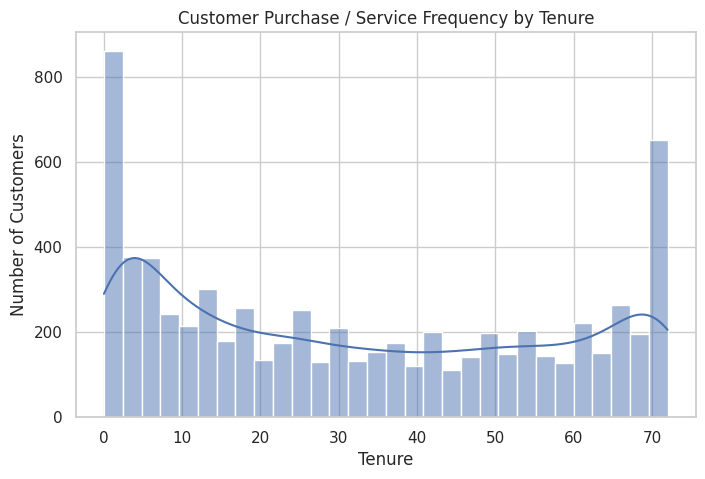

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


In [ ]:
# 1. Purchase Frequency Analysis
# In telco churn data, tenure can be used as a proxy for customer purchase/service duration

if "tenure" in df.columns:
    plt.figure()
    sns.histplot(df["tenure"], bins=30, kde=True)
    plt.title("Customer Purchase / Service Frequency by Tenure")
    plt.xlabel("Tenure")
    plt.ylabel("Number of Customers")
    plt.show()

    print(df["tenure"].describe())

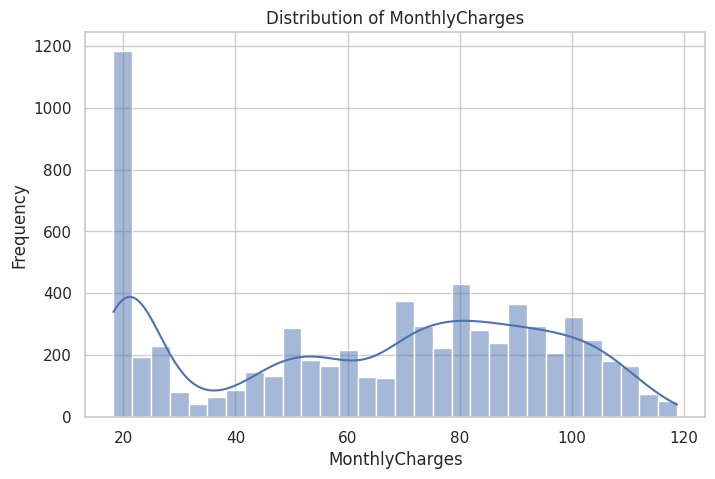

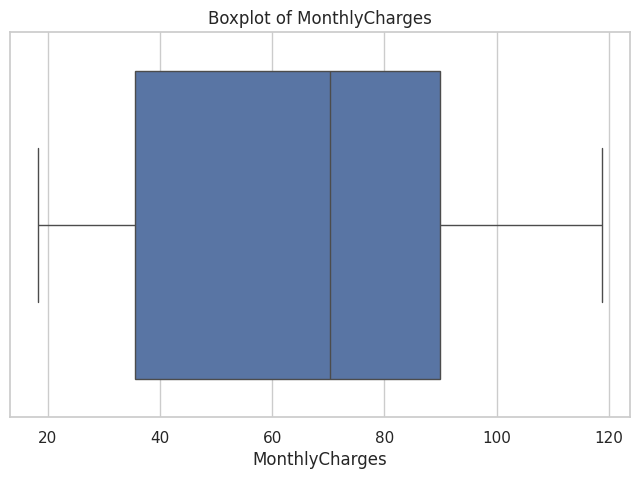

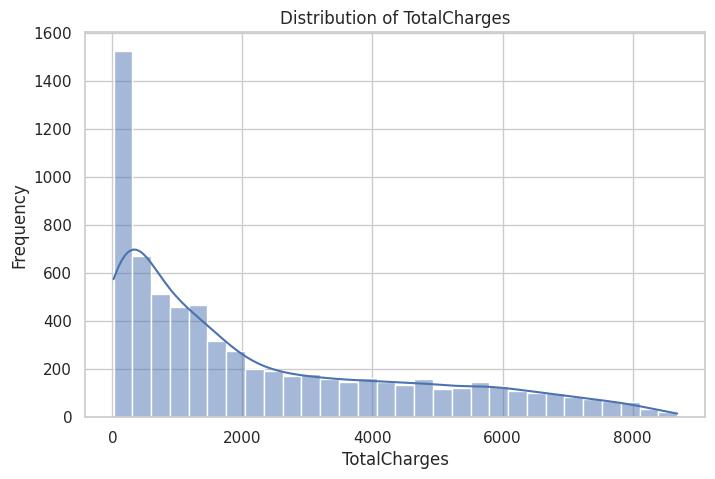

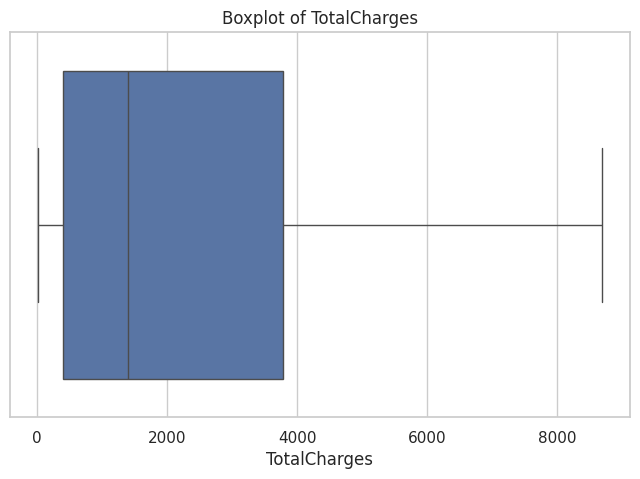

In [ ]:
# 2. Spending Distribution Analysis

spending_cols = ["MonthlyCharges", "TotalCharges"]

for col in spending_cols:
    if col in df.columns:
        plt.figure()
        sns.histplot(df[col], bins=30, kde=True)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

        plt.figure()
        sns.boxplot(x=df[col])
        plt.title(f"Boxplot of {col}")
        plt.xlabel(col)
        plt.show()

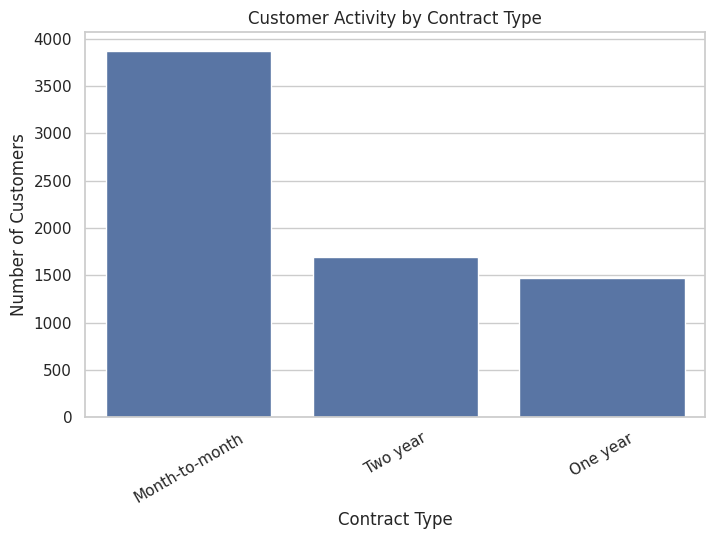

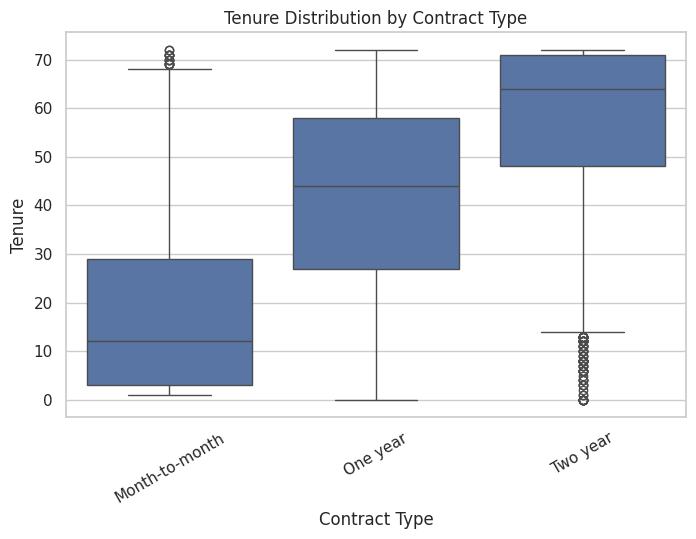

In [ ]:
# 3. Customer Activity Trends

if "Contract" in df.columns:
    plt.figure()
    sns.countplot(data=df, x="Contract", order=df["Contract"].value_counts().index)
    plt.title("Customer Activity by Contract Type")
    plt.xlabel("Contract Type")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)
    plt.show()

if "tenure" in df.columns and "Contract" in df.columns:
    plt.figure()
    sns.boxplot(data=df, x="Contract", y="tenure")
    plt.title("Tenure Distribution by Contract Type")
    plt.xlabel("Contract Type")
    plt.ylabel("Tenure")
    plt.xticks(rotation=30)
    plt.show()

Revenue Contribution by Contract:
Contract
Two year          6297228.450
Month-to-month    5305861.500
One year          4468450.975
Name: TotalCharges, dtype: float64


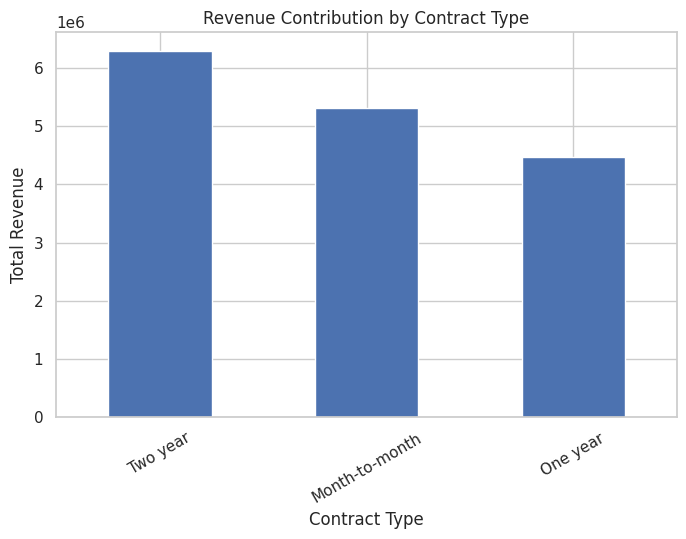

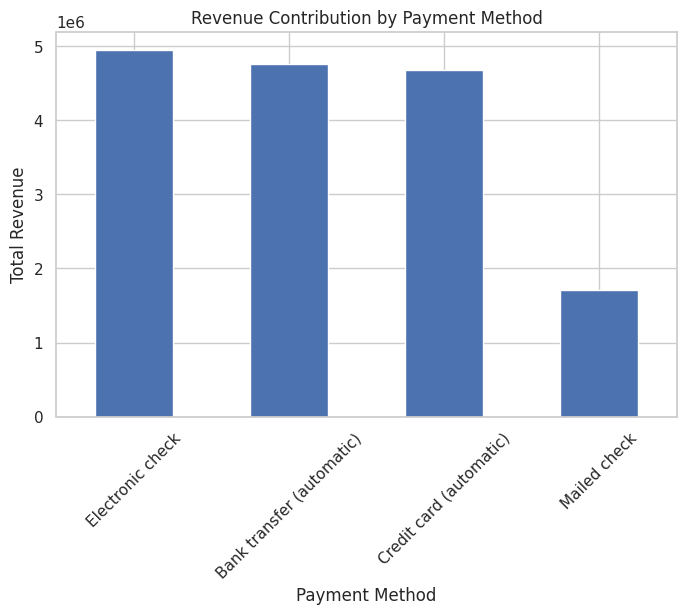

In [ ]:
# 4. Revenue Contribution Analysis

if "Contract" in df.columns and "TotalCharges" in df.columns:
    revenue_by_contract = (
        df.groupby("Contract")["TotalCharges"]
        .sum()
        .sort_values(ascending=False)
    )

    print("Revenue Contribution by Contract:")
    print(revenue_by_contract)

    plt.figure()
    revenue_by_contract.plot(kind="bar")
    plt.title("Revenue Contribution by Contract Type")
    plt.xlabel("Contract Type")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=30)
    plt.show()

if "PaymentMethod" in df.columns and "TotalCharges" in df.columns:
    revenue_by_payment = (
        df.groupby("PaymentMethod")["TotalCharges"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure()
    revenue_by_payment.plot(kind="bar")
    plt.title("Revenue Contribution by Payment Method")
    plt.xlabel("Payment Method")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=45)
    plt.show()

Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


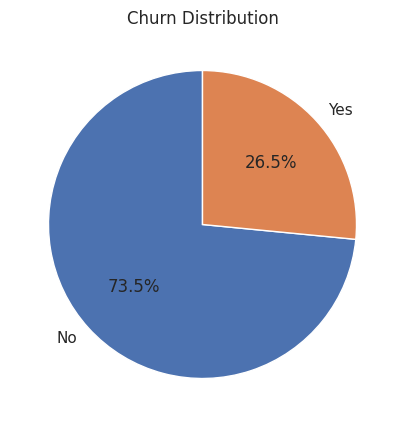

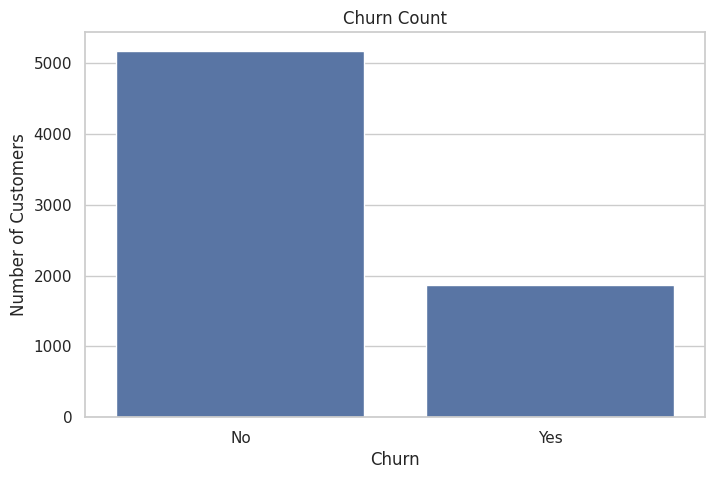

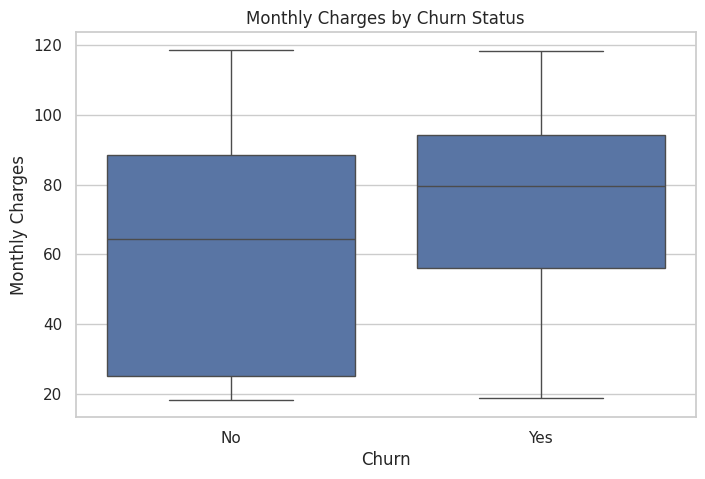

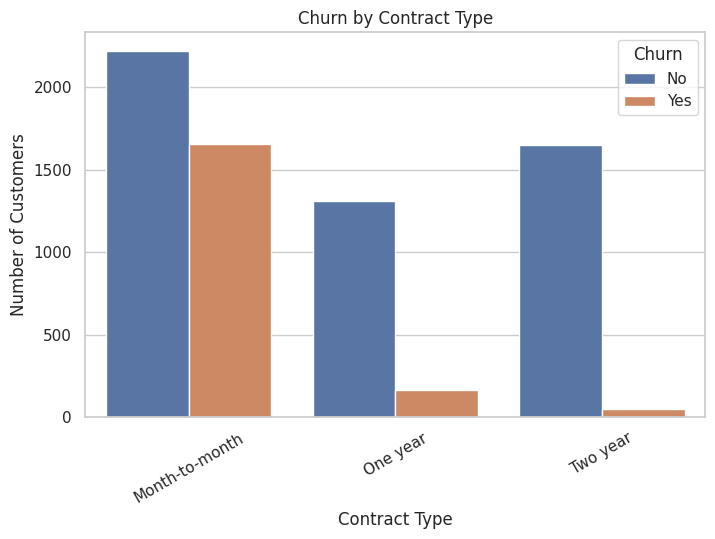

In [ ]:
# 5. Churn Analysis

if "Churn" in df.columns:
    churn_counts = df["Churn"].value_counts()

    print("Churn Counts:")
    print(churn_counts)

    plt.figure()
    churn_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
    plt.title("Churn Distribution")
    plt.ylabel("")
    plt.show()

    plt.figure()
    sns.countplot(data=df, x="Churn")
    plt.title("Churn Count")
    plt.xlabel("Churn")
    plt.ylabel("Number of Customers")
    plt.show()

if "Churn" in df.columns and "MonthlyCharges" in df.columns:
    plt.figure()
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.title("Monthly Charges by Churn Status")
    plt.xlabel("Churn")
    plt.ylabel("Monthly Charges")
    plt.show()

if "Churn" in df.columns and "Contract" in df.columns:
    plt.figure()
    sns.countplot(data=df, x="Contract", hue="Churn")
    plt.title("Churn by Contract Type")
    plt.xlabel("Contract Type")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)
    plt.show()

Correlation Matrix:
                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen             NaN       NaN             NaN           NaN
tenure                    NaN  1.000000        0.247900      0.825464
MonthlyCharges            NaN  0.247900        1.000000      0.650864
TotalCharges              NaN  0.825464        0.650864      1.000000


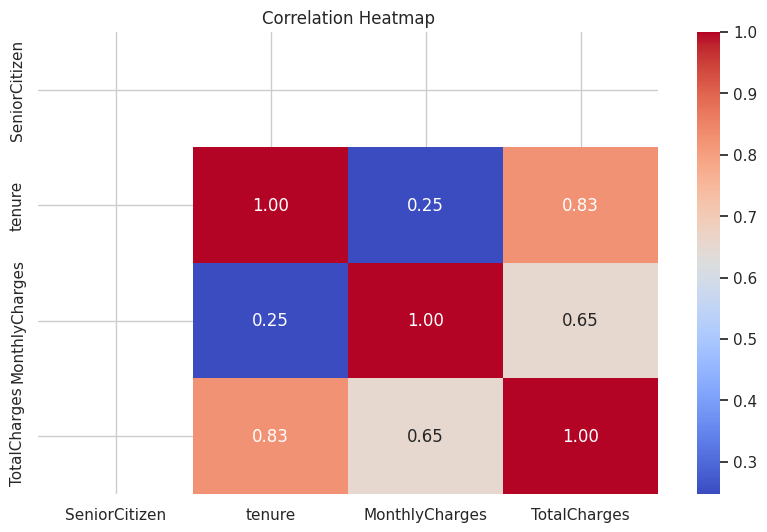

In [ ]:
# 6. Correlation Analysis

numeric_df = df.select_dtypes(include=["int64", "float64"])

if not numeric_df.empty:
    correlation_matrix = numeric_df.corr()

    print("Correlation Matrix:")
    print(correlation_matrix)

    plt.figure(figsize=(10, 6))
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.show()

In [ ]:
# 7. Time-Series Analysis
# This will work only if date columns exist in your dataset

for date_col in date_columns:
    if date_col in df.columns:
        temp_df = df.dropna(subset=[date_col]).copy()

        if not temp_df.empty:
            temp_df["Month"] = temp_df[date_col].dt.to_period("M").astype(str)

            monthly_customers = temp_df.groupby("Month").size()

            plt.figure(figsize=(10, 5))
            monthly_customers.plot(kind="line", marker="o")
            plt.title(f"Customer Activity Trend Over Time using {date_col}")
            plt.xlabel("Month")
            plt.ylabel("Number of Customers")
            plt.xticks(rotation=45)
            plt.show()

In [ ]:
# Load cleaned dataset
df = pd.read_csv("/content/Cleaned_Telco_Customer_Churn.csv")

# Convert date columns to datetime if they exist
date_columns = ["SignupDate", "ContractStartDate", "ContractEndDate", "LastPurchaseDate", "InvoiceDate"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# -------------------------------
# 1. Customer Tenure
# -------------------------------

if "tenure" in df.columns:
    df["Customer_Tenure"] = df["tenure"]

elif "ContractStartDate" in df.columns:
    reference_date = pd.Timestamp.today()
    df["Customer_Tenure"] = (
        reference_date - df["ContractStartDate"]
    ).dt.days

# -------------------------------
# 2. Monetary Value
# -------------------------------

if "TotalCharges" in df.columns:
    df["Monetary_Value"] = df["TotalCharges"]

# -------------------------------
# 3. Monthly Spending
# -------------------------------

if "MonthlyCharges" in df.columns:
    df["Monthly_Spending"] = df["MonthlyCharges"]

# -------------------------------
# 4. Frequency
# -------------------------------
# If transaction-level data exists, count customer purchases.
# If not, tenure is used as an approximate activity measure.

if "customerID" in df.columns and "TransactionID" in df.columns:
    df["Frequency"] = df.groupby("customerID")["TransactionID"].transform("count")

elif "tenure" in df.columns:
    df["Frequency"] = df["tenure"]

# -------------------------------
# 5. Total Transactions
# -------------------------------

if "customerID" in df.columns and "TransactionID" in df.columns:
    df["Total_Transactions"] = df.groupby("customerID")["TransactionID"].transform("count")

else:
    df["Total_Transactions"] = 1

# -------------------------------
# 6. Average Order Value
# -------------------------------

if "TotalCharges" in df.columns and "Total_Transactions" in df.columns:
    df["Average_Order_Value"] = df["TotalCharges"] / df["Total_Transactions"]
    df["Average_Order_Value"] = df["Average_Order_Value"].replace([np.inf, -np.inf], np.nan)
    df["Average_Order_Value"] = df["Average_Order_Value"].fillna(0)

# -------------------------------
# 7. Recency
# -------------------------------
# Recency = number of days since last purchase/activity

if "LastPurchaseDate" in df.columns:
    reference_date = df["LastPurchaseDate"].max()
    df["Recency"] = (reference_date - df["LastPurchaseDate"]).dt.days

elif "ContractEndDate" in df.columns:
    reference_date = df["ContractEndDate"].max()
    df["Recency"] = (reference_date - df["ContractEndDate"]).dt.days

else:
    df["Recency"] = np.nan

# -------------------------------
# 8. Days Since Last Purchase
# -------------------------------

if "LastPurchaseDate" in df.columns:
    today = pd.Timestamp.today()
    df["Days_Since_Last_Purchase"] = (
        today - df["LastPurchaseDate"]
    ).dt.days

else:
    df["Days_Since_Last_Purchase"] = df["Recency"]

# -------------------------------
# 9. Product Diversity
# -------------------------------
# Counts number of different products/services used by each customer

service_columns = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

available_service_cols = [col for col in service_columns if col in df.columns]

if available_service_cols:
    df["Product_Diversity"] = df[available_service_cols].apply(
        lambda row: sum(
            value not in ["No", "No internet service", "No phone service", np.nan]
            for value in row
        ),
        axis=1
    )

# -------------------------------
# 10. Engagement Frequency
# -------------------------------
# Approximate engagement using tenure and product diversity

if "Customer_Tenure" in df.columns and "Product_Diversity" in df.columns:
    df["Engagement_Frequency"] = df["Product_Diversity"] / (df["Customer_Tenure"] + 1)

elif "Frequency" in df.columns:
    df["Engagement_Frequency"] = df["Frequency"]

# Save feature-engineered dataset
output_path = "/content/Feature_Engineered_Telco_Customer_Churn.csv"
df.to_csv(output_path, index=False)

print("Feature engineering completed successfully.")
print("Feature-engineered file saved at:", output_path)

# Display new features
new_features = [
    "Recency",
    "Frequency",
    "Monetary_Value",
    "Customer_Tenure",
    "Average_Order_Value",
    "Total_Transactions",
    "Days_Since_Last_Purchase",
    "Monthly_Spending",
    "Product_Diversity",
    "Engagement_Frequency"
]

available_features = [col for col in new_features if col in df.columns]

print(df[available_features].head())

Feature engineering completed successfully.
Feature-engineered file saved at: /content/Feature_Engineered_Telco_Customer_Churn.csv
   Recency  Frequency  Monetary_Value  Customer_Tenure  Average_Order_Value  \
0      NaN        1.0           29.85              1.0                29.85   
1      NaN       34.0         1889.50             34.0              1889.50   
2      NaN        2.0          108.15              2.0               108.15   
3      NaN       45.0         1840.75             45.0              1840.75   
4      NaN        2.0          151.65              2.0               151.65   

   Total_Transactions  Days_Since_Last_Purchase  Monthly_Spending  \
0                   1                       NaN             29.85   
1                   1                       NaN             56.95   
2                   1                       NaN             53.85   
3                   1                       NaN             42.30   
4                   1                       NaN  

### Additional Feature Engineering

Based on your feedback, I will add more business-oriented features to enhance our dataset for better modeling. These include:

*   **Average Revenue per Month**: Calculated from `TotalCharges` and `tenure`.
*   **Tenure Buckets**: Categorizing customers into groups based on their `tenure`.
*   **Service Usage Intensity**: Using the existing `Product_Diversity` feature as a direct measure of how many services a customer is actively using.
*   **Has Tech Support**: A binary indicator derived from the `TechSupport` column, acting as a proxy for customer support interactions.


### Enhanced Feature Engineering: Business-Driven Features

Beyond the initial feature engineering, incorporating more business-specific metrics can significantly boost model performance and interpretability. The following features were added based on common business insights in the telecommunications industry:

*   **Average Revenue per Month**: This is a direct measure of a customer's monthly value to the business. It normalizes `TotalCharges` by `tenure`, giving a consistent view of revenue generation, especially useful for understanding trends and comparing customers with varying contract lengths.
*   **Tenure Buckets**: Categorizing continuous `tenure` into discrete buckets (e.g., '0-12 Months', '13-24 Months') simplifies interpretation and can capture non-linear relationships with churn or CLV. Different strategies might apply to new customers versus long-term customers.
*   **Service Usage Intensity**: Using the existing `Product_Diversity` (number of services) directly as 'Service_Usage_Intensity' provides a clearer, business-focused name for a metric indicating how deeply integrated a customer is with the provider's ecosystem. Higher intensity often correlates with lower churn.
*   **Has Tech Support**: `TechSupport` is a critical indicator of customer engagement and potential issues. A binary 'Has_Tech_Support' flag serves as a proxy for customer support interactions. Customers who engage with tech support might be at higher risk of churn if their issues are unresolved, or conversely, more loyal if their issues are handled well.

In [ ]:
# Load the feature-engineered dataset from the previous step
df = pd.read_csv('/content/Feature_Engineered_Telco_Customer_Churn.csv')

# Ensure 'tenure' and 'TotalCharges' are numeric
df['tenure'] = pd.to_numeric(df['tenure'], errors='coerce').fillna(0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce').fillna(0)

# 1. Average Revenue per Month
# Handle division by zero for tenure: if tenure is 0, use MonthlyCharges as proxy
df['Avg_Revenue_Per_Month'] = df.apply(
    lambda row: row['TotalCharges'] / row['tenure'] if row['tenure'] > 0 else row['MonthlyCharges'],
    axis=1
)

# 2. Tenure Buckets
# Define bins and labels for tenure
tenure_bins = [0, 12, 24, 48, 72, np.inf]
tenure_labels = ['0-12 Months', '13-24 Months', '25-48 Months', '49-72 Months', '72+ Months']
df['Tenure_Bucket'] = pd.cut(
    df['tenure'],
    bins=tenure_bins,
    labels=tenure_labels,
    right=False,
    include_lowest=True
).astype(str) # Convert to string to avoid issues with categorical type in later processing

# 3. Service Usage Intensity (Product_Diversity already exists and serves this purpose)
# Renaming for clarity based on user's suggestion
df['Service_Usage_Intensity'] = df['Product_Diversity']

# 4. Customer Support Interactions (using TechSupport as a proxy)
# Map 'Yes' to 1, 'No' and 'No internet service' to 0
df['Has_Tech_Support'] = df['TechSupport'].map({'Yes': 1, 'No': 0, 'No internet service': 0}).fillna(0).astype(int)

# Save the updated feature-engineered dataset
output_path = "/content/Feature_Engineered_Telco_Customer_Churn.csv"
df.to_csv(output_path, index=False)

print("Additional feature engineering completed successfully.")
print("Updated feature-engineered file saved at:", output_path)

print("\nNewly added features (head):")
display(df[[
    'Avg_Revenue_Per_Month',
    'Tenure_Bucket',
    'Service_Usage_Intensity',
    'Has_Tech_Support'
]].head())

Additional feature engineering completed successfully.
Updated feature-engineered file saved at: /content/Feature_Engineered_Telco_Customer_Churn.csv

Newly added features (head):


,Avg_Revenue_Per_Month,Tenure_Bucket,Service_Usage_Intensity,Has_Tech_Support
0,29.850000,0-12 Months,2,0
1,55.573529,25-48 Months,4,0
2,54.075000,0-12 Months,4,0
3,40.905556,25-48 Months,4,1
4,75.825000,0-12 Months,2,0


In [ ]:
# Load feature-engineered dataset
df = pd.read_csv("/content/Feature_Engineered_Telco_Customer_Churn.csv")

# -------------------------------
# RFM Feature Preparation
# -------------------------------

# Recency
# Lower recency means the customer purchased more recently.
if "Recency" not in df.columns:
    df["Recency"] = np.nan

# If Recency is missing, approximate it using tenure.
# This is useful for Telco churn data without purchase dates.
if df["Recency"].isnull().all():
    if "Customer_Tenure" in df.columns:
        df["Recency"] = df["Customer_Tenure"].max() - df["Customer_Tenure"]
    elif "tenure" in df.columns:
        df["Recency"] = df["tenure"].max() - df["tenure"]
    else:
        df["Recency"] = 0

# Frequency
if "Frequency" not in df.columns:
    if "Total_Transactions" in df.columns:
        df["Frequency"] = df["Total_Transactions"]
    elif "tenure" in df.columns:
        df["Frequency"] = df["tenure"]
    else:
        df["Frequency"] = 1

# Monetary Value
if "Monetary_Value" not in df.columns:
    if "TotalCharges" in df.columns:
        df["Monetary_Value"] = df["TotalCharges"]
    elif "MonthlyCharges" in df.columns:
        df["Monetary_Value"] = df["MonthlyCharges"]
    else:
        df["Monetary_Value"] = 0

# Keep only required RFM fields
rfm = df[["Recency", "Frequency", "Monetary_Value"]].copy()

# Replace invalid values
rfm.replace([np.inf, -np.inf], np.nan, inplace=True)
rfm.fillna(rfm.median(numeric_only=True), inplace=True)

# -------------------------------
# RFM Score Calculation
# -------------------------------

# Recency: lower values are better
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher values are better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher values are better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary_Value"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm["RFM_Total"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# -------------------------------
# Customer Segmentation
# -------------------------------

def assign_rfm_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]
    total = row["RFM_Total"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4 and m >= 3:
        return "Loyal Customers"

    elif r >= 4 and f <= 3:
        return "Potential Loyalists"

    elif r == 5 and f <= 2 and m <= 2:
        return "New Customers"

    elif r <= 2 and f >= 3 and m >= 3:
        return "At-Risk Customers"

    elif r <= 2 and f <= 2:
        return "Lost Customers"

    else:
        return "Others"

rfm["RFM_Segment"] = rfm.apply(assign_rfm_segment, axis=1)

# Add RFM results back to main dataframe
df = pd.concat([df, rfm], axis=1)

# Save segmented dataset
output_path = "/content/RFM_Segmented_Telco_Customer_Churn.csv"
df.to_csv(output_path, index=False)

print("RFM customer segmentation completed successfully.")
print("Segmented dataset saved at:", output_path)

print("\nRFM Segment Counts:")
print(df["RFM_Segment"].value_counts())

print("\nSample RFM Output:")
print(df[[
    "Recency",
    "Frequency",
    "Monetary_Value",
    "R_Score",
    "F_Score",
    "M_Score",
    "RFM_Score",
    "RFM_Total",
    "RFM_Segment"
]].head())

RFM customer segmentation completed successfully.
Segmented dataset saved at: /content/RFM_Segmented_Telco_Customer_Churn.csv

RFM Segment Counts:
RFM_Segment
Lost Customers         2807
Champions              2196
Others                 1491
Loyal Customers         538
At-Risk Customers         7
Potential Loyalists       4
Name: count, dtype: int64

Sample RFM Output:
   Recency  Recency  Frequency  Frequency  Monetary_Value  Monetary_Value  \
0     71.0     71.0        1.0        1.0           29.85           29.85   
1     38.0     38.0       34.0       34.0         1889.50         1889.50   
2     70.0     70.0        2.0        2.0          108.15          108.15   
3     27.0     27.0       45.0       45.0         1840.75         1840.75   
4     70.0     70.0        2.0        2.0          151.65          151.65   

   R_Score  F_Score  M_Score RFM_Score  RFM_Total      RFM_Segment  
0        1        1        1       111          3   Lost Customers  
1        3        3       

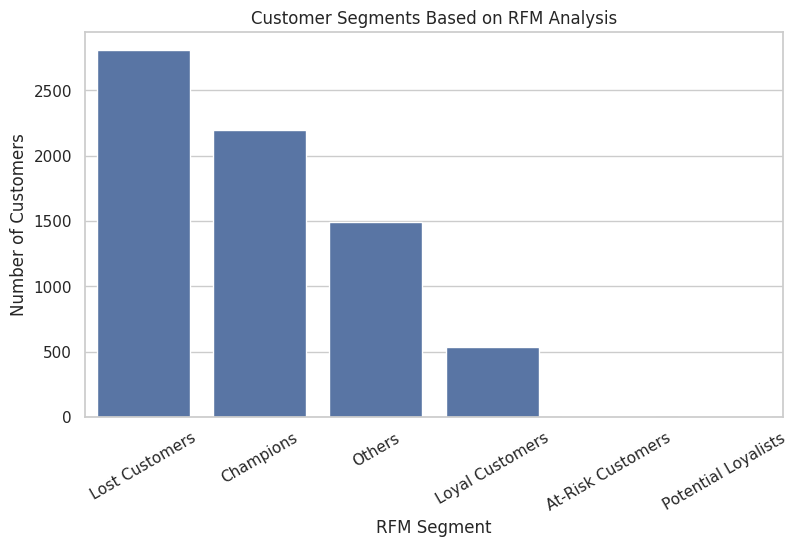

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="RFM_Segment",
    order=df["RFM_Segment"].value_counts().index
)
plt.title("Customer Segments Based on RFM Analysis")
plt.xlabel("RFM Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.show()

                       Recency    Recency  Frequency  Frequency  \
RFM_Segment                                                       
Champions            12.438069  12.438069  59.561931  59.561931   
Loyal Customers      12.239777  12.239777  59.760223  59.760223   
Potential Loyalists  32.000000  32.000000  40.000000  40.000000   
Others               42.127431  42.127431  29.872569  29.872569   
At-Risk Customers    52.000000  52.000000  20.000000  20.000000   
Lost Customers       64.803349  64.803349   7.196651   7.196651   

                     Monetary_Value  Monetary_Value  RFM_Total  
RFM_Segment                                                     
Champions               5175.219718     5175.219718  13.672587  
Loyal Customers         1419.560502     1419.560502  12.029740  
Potential Loyalists     2637.875000     2637.875000  10.750000  
Others                  1815.719651     1815.719651   9.232730  
At-Risk Customers       1551.557143     1551.557143   8.000000  
Lost Cus

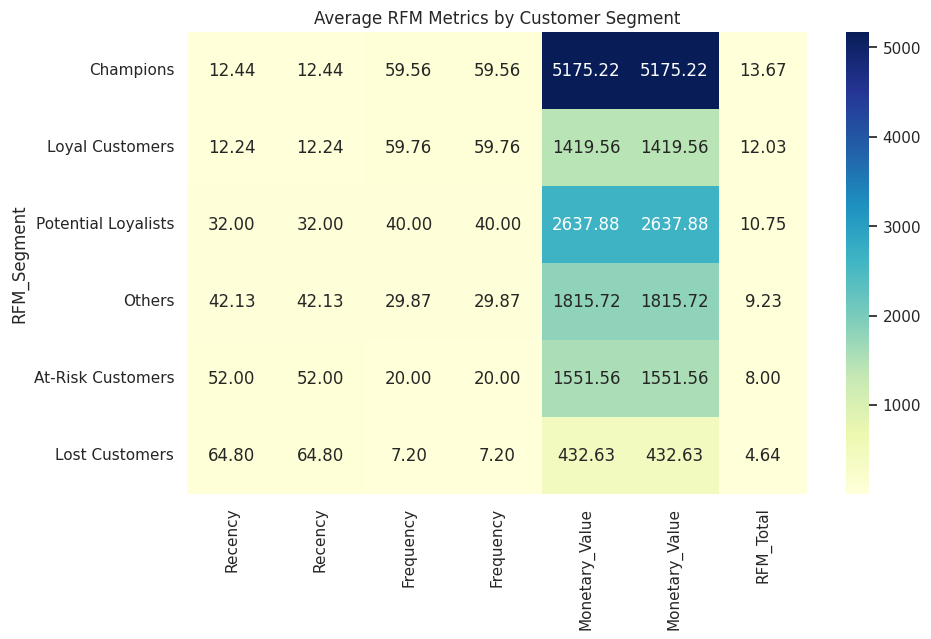

In [ ]:
segment_summary = df.groupby("RFM_Segment")[[
    "Recency",
    "Frequency",
    "Monetary_Value",
    "RFM_Total"
]].mean().sort_values(by="RFM_Total", ascending=False)

print(segment_summary)

plt.figure(figsize=(10, 6))
sns.heatmap(segment_summary, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Average RFM Metrics by Customer Segment")
plt.show()

### Business Interpretation of RFM Segments

Understanding these RFM segments provides actionable insights for targeted marketing and customer management strategies:

*   **Champions**: These are your best customers. They bought recently, buy often, and spend the most. **Action**: Reward them, engage them with new product launches, and encourage advocacy.
*   **Loyal Customers**: These customers buy regularly. **Action**: Upsell high-value products, provide loyalty programs, and ask for referrals.
*   **Potential Loyalists**: Recent customers who have spent a good amount but haven't bought frequently. **Action**: Offer membership or loyalty programs to increase frequency, provide personalized product recommendations.
*   **New Customers**: Very recent but low frequency and monetary value. **Action**: Focus on onboarding, initial engagement campaigns, and nurturing to move them towards 'Loyal Customers'.
*   **At-Risk Customers**: Customers who bought long ago, bought few times, and spent little. **Action**: Send personalized re-engagement offers, address potential issues, or collect feedback to understand why they are disengaging.
*   **Lost Customers**: These customers haven't purchased for a long time and have low engagement. **Action**: Launch reactivation campaigns with aggressive offers, or consider them as lost and focus resources elsewhere.
*   **Others**: This segment represents a mix of customers who don't clearly fit into the more defined RFM categories. Further analysis might be needed to understand their specific behaviors or to refine segmentation rules. They might be casual shoppers or customers in transition.

In [ ]:
# Features used for clustering
features_used = [
    'Recency',
    'Frequency',
    'Monetary_Value',
    'Customer_Tenure',
    'Average_Order_Value',
    'Total_Transactions',
    'Days_Since_Last_Purchase',
    'Monthly_Spending',
    'Product_Diversity',
    'Engagement_Frequency',
    'RFM_Total'
]

# Create feature matrix
X = df[features_used].copy()

# Fix: Ensure X has unique column names
# The previous `pd.concat` operation might have created duplicate column names.
# When `X[col]` is accessed and `col` is a duplicated name, it returns a DataFrame
# instead of a Series. Applying `nunique()` to this DataFrame results in a Series,
# and comparing it (`Series <= 1`) results in a Series of booleans.
# This Series of booleans is ambiguous in a truth-value context, causing the ValueError.
# We explicitly drop duplicate columns, keeping the first occurrence.
X = X.loc[:, ~X.columns.duplicated()].copy()

# Replace infinite values with NaN
X.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove columns that are completely NaN
all_nan_cols = X.columns[X.isna().all()].tolist()
if all_nan_cols:
    print("Dropping all-NaN columns:", all_nan_cols)
    X.drop(columns=all_nan_cols, inplace=True)

# Fill NaN values with median of each column
for col in X.columns:
    X[col] = X[col].fillna(X[col].median())

# Remove constant columns (zero variance)
constant_cols = [col for col in X.columns if X[col].nunique() <= 1]
if constant_cols:
    print("Dropping constant columns:", constant_cols)
    X.drop(columns=constant_cols, inplace=True)

# Final validation
print("\nRemaining NaNs:", X.isna().sum().sum())
print("Remaining Infs:", np.isinf(X.values).sum())

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data cleaned and scaled successfully.")
print("Shape:", X_scaled.shape)

Dropping all-NaN columns: ['Days_Since_Last_Purchase']
Dropping constant columns: ['Total_Transactions']

Remaining NaNs: 0
Remaining Infs: 0
Data cleaned and scaled successfully.
Shape: (7043, 9)


## Why Clustering?

Clustering is a powerful unsupervised machine learning technique used to group customers (or data points) based on similarities in their features without any prior knowledge of group labels. In this context, clustering helps us achieve several key business objectives:

1.  **Customer Segmentation**: It allows us to discover natural groupings within our customer base. Instead of treating all customers uniformly, we can identify distinct segments with shared characteristics, needs, and behaviors.
2.  **Targeted Strategies**: Once segments are identified, marketing, sales, and customer service teams can tailor their strategies to the specific needs and preferences of each group. For example, high-value, active customers might receive loyalty rewards, while at-risk customers could be targeted with retention campaigns.
3.  **Improved Understanding**: Clustering provides insights into the structure of the customer data, revealing patterns that might not be obvious through simple aggregations or manual inspection. This deeper understanding can inform product development, pricing strategies, and overall business decisions.
4.  **Foundation for Predictive Models**: Identified clusters can sometimes be used as features in subsequent predictive models (like churn prediction or CLV prediction), potentially enhancing their accuracy by incorporating latent group information.

We employ methods like the Elbow Method and Silhouette Score to determine the optimal number of clusters, ensuring that the resulting segments are meaningful and distinct.

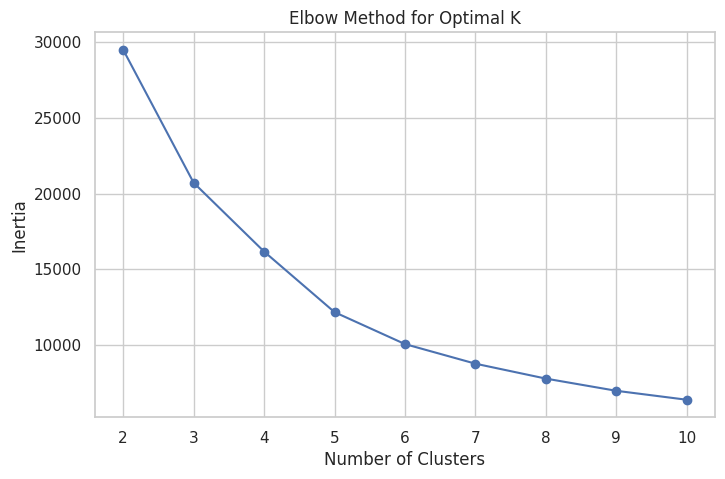

In [ ]:
from sklearn.cluster import KMeans

# -------------------------------
# Elbow Method for K-Means
# -------------------------------

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.show()

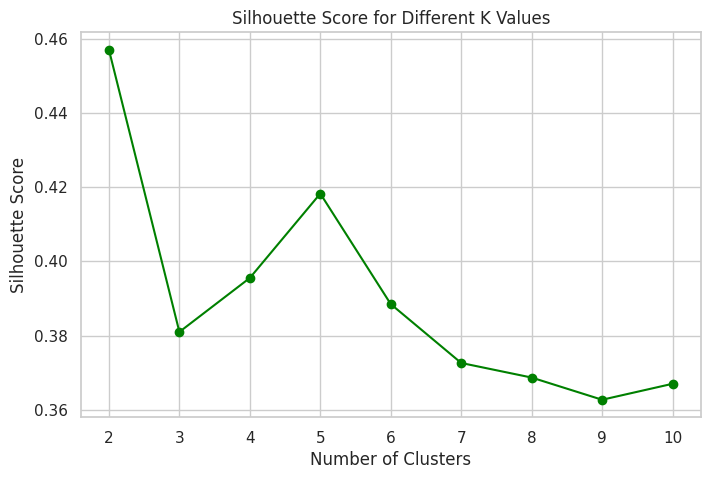

Best number of clusters based on silhouette score: 2


In [ ]:
# -------------------------------
# Silhouette Score Evaluation
# -------------------------------

silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o", color="green")
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.show()

best_k = k_values[np.argmax(silhouette_scores)]
print("Best number of clusters based on silhouette score:", best_k)

In [ ]:
# Define k_values, assuming it's consistent with previous cells
k_values = range(2, 11)

# Re-calculate silhouette scores to define best_k
silhouette_scores = []

for k in k_values:
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

best_k = k_values[np.argmax(silhouette_scores)]

# -------------------------------
# K-Means Clustering
# -------------------------------

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

K-Means Cluster Counts:
KMeans_Cluster
0    4007
1    3036
Name: count, dtype: int64


Explained Variance Ratio:
[0.71944444 0.19606498]


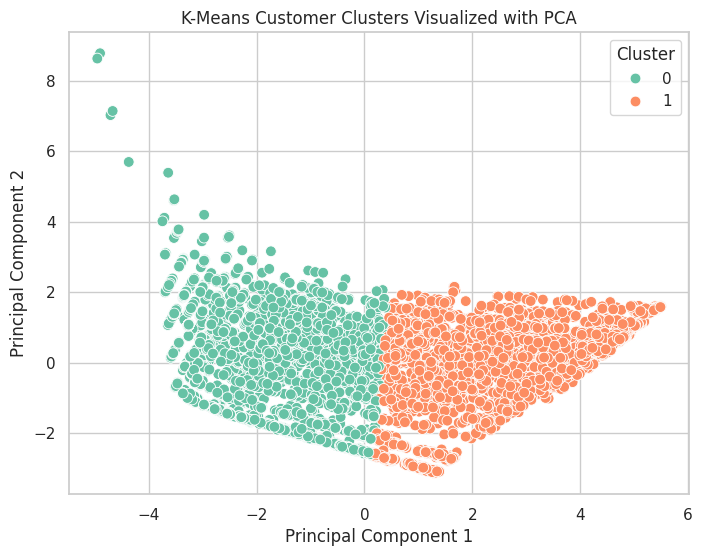

In [ ]:
# -------------------------------
# PCA for Visualization
# -------------------------------

pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)

df["PCA1"] = pca_components[:, 0]
df["PCA2"] = pca_components[:, 1]

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="Set2",
    s=60
)
plt.title("K-Means Customer Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    3888
1    3155
Name: count, dtype: int64


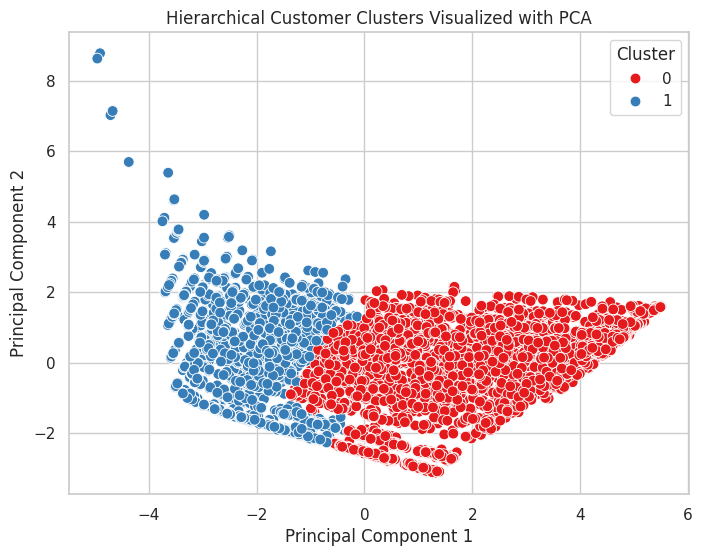

In [ ]:
# -------------------------------
# Hierarchical Clustering
# -------------------------------

hierarchical = AgglomerativeClustering(n_clusters=best_k)
df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("Hierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="Hierarchical_Cluster",
    palette="Set1",
    s=60
)
plt.title("Hierarchical Customer Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

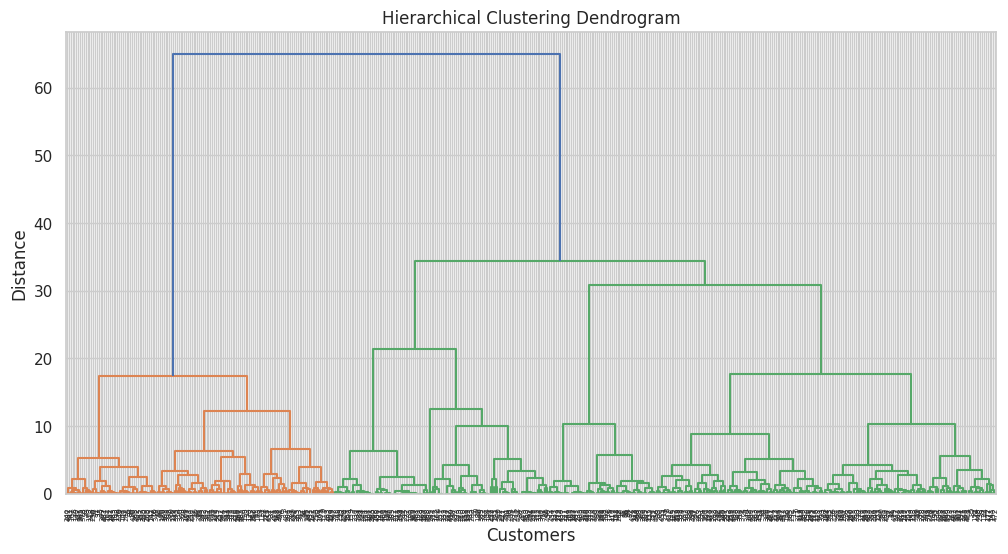

In [ ]:
# -------------------------------
# Optional Dendrogram
# -------------------------------

# Use sample for readability
sample_size = min(500, X_scaled.shape[0])
X_sample = X_scaled[:sample_size]

linked = linkage(X_sample, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

K-Means Cluster Profile:
                  Recency    Recency  Frequency  Frequency  Monetary_Value  \
KMeans_Cluster                                                               
0               57.945096  57.945096  14.054904  14.054904      704.710613   
1               15.454545  15.454545  56.545455  56.545455     4363.559124   

                Monetary_Value  Customer_Tenure  Average_Order_Value  \
KMeans_Cluster                                                         
0                   704.710613        14.054904           704.710613   
1                  4363.559124        56.545455          4363.559124   

                Total_Transactions  Days_Since_Last_Purchase  \
KMeans_Cluster                                                 
0                              1.0                       NaN   
1                              1.0                       NaN   

                Monthly_Spending  Product_Diversity  Engagement_Frequency  \
KMeans_Cluster                         

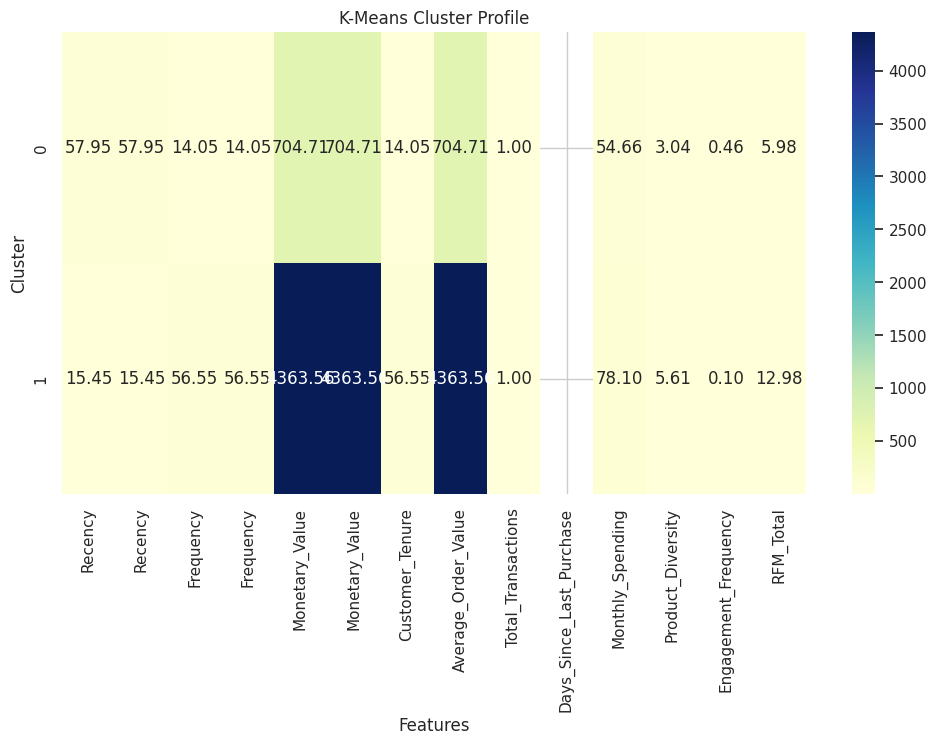

In [ ]:
# -------------------------------
# Cluster Profiling
# -------------------------------

features = [
    'Recency',
    'Frequency',
    'Monetary_Value',
    'Customer_Tenure',
    'Average_Order_Value',
    'Total_Transactions',
    'Days_Since_Last_Purchase',
    'Monthly_Spending',
    'Product_Diversity',
    'Engagement_Frequency',
    'RFM_Total'
]

# Filter out features that might have been dropped during preprocessing
# For example, 'Days_Since_Last_Purchase' and 'Total_Transactions' were dropped in cell G06OH3Q1u5Gb
features = [f for f in features if f in df.columns]

cluster_profile = df.groupby("KMeans_Cluster")[features].mean()

print("K-Means Cluster Profile:")
print(cluster_profile)

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_profile, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("K-Means Cluster Profile")
plt.xlabel("Features")
plt.ylabel("Cluster")
plt.show()

In [ ]:
# Add readable labels based on cluster profiles

def label_clusters(profile):
    labels = {}

    # Ensure profile has unique column names to avoid Series ambiguity
    # This happens because the original df had duplicated columns after concat with rfm.
    profile = profile.loc[:, ~profile.columns.duplicated()]

    for cluster_id, row in profile.iterrows():
        # Ensure we are getting scalar values for comparison
        monetary = row["Monetary_Value"]
        frequency = row["Frequency"]
        recency = row["Recency"]

        # Now, profile["Feature"].median() will return a scalar as columns are unique
        if monetary >= profile["Monetary_Value"].median() and frequency >= profile["Frequency"].median():
            labels[cluster_id] = "High Value Customers"

        elif recency >= profile["Recency"].median() and frequency <= profile["Frequency"].median():
            labels[cluster_id] = "Inactive Customers"

        elif frequency >= profile["Frequency"].median():
            labels[cluster_id] = "Frequent Customers"

        else:
            labels[cluster_id] = "Low Value Customers"

    return labels

cluster_labels = label_clusters(cluster_profile)

df["Cluster_Label"] = df["KMeans_Cluster"].map(cluster_labels)

print("Cluster Labels:")
print(cluster_labels)

print("\nCluster Label Counts:")
print(df["Cluster_Label"].value_counts())

Cluster Labels:
{0: 'Inactive Customers', 1: 'High Value Customers'}

Cluster Label Counts:
Cluster_Label
Inactive Customers      4007
High Value Customers    3036
Name: count, dtype: int64


### Business Interpretation of K-Means Clusters

The K-Means clusters, profiled by the average feature values, offer valuable insights into distinct customer behaviors. For the identified `best_k` clusters:

*   **Cluster 0: Inactive Customers**: This cluster generally shows higher recency (meaning their last activity was longer ago), lower frequency, and lower monetary value. They also have lower customer tenure and engagement frequency. This segment likely represents customers who are either relatively new and haven't engaged much, or older customers who are becoming dormant. **Business Action**: Implement re-engagement campaigns, special offers to entice them back, or focus on understanding reasons for their inactivity.

*   **Cluster 1: High Value Customers**: This cluster exhibits lower recency (meaning recent activity), higher frequency, and significantly higher monetary value. They tend to have longer customer tenure and higher product diversity and engagement. These are your most valuable and engaged customers. **Business Action**: Focus on loyalty programs, exclusive offers, upselling/cross-selling premium services, and encouraging referrals to maximize their lifetime value.

In [ ]:
# Save final clustered dataset

output_path = "/content/Clustered_Telco_Customer_Churn.csv"
df.to_csv(output_path, index=False)

print("Clustering-based customer segmentation completed successfully.")
print("Clustered dataset saved at:", output_path)

Clustering-based customer segmentation completed successfully.
Clustered dataset saved at: /content/Clustered_Telco_Customer_Churn.csv


In [ ]:
# Optional: install advanced models if not already available
!pip install xgboost lightgbm -q

In [ ]:
# Load final dataset
df = pd.read_csv("/content/Clustered_Telco_Customer_Churn.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (7043, 45)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female            0.0     Yes         No     1.0           No   
1  5575-GNVDE    Male            0.0      No         No    34.0          Yes   
2  3668-QPYBK    Male            0.0      No         No     2.0          Yes   
3  7795-CFOCW    Male            0.0      No         No    45.0           No   
4  9237-HQITU  Female            0.0      No         No     2.0          Yes   

      MultipleLines InternetService OnlineSecurity  ... F_Score M_Score  \
0  No phone service             DSL             No  ...       1       1   
1                No             DSL            Yes  ...       3       3   
2                No             DSL            Yes  ...       1       1   
3  No phone service             DSL            Yes  ...       4       3   
4                No     Fiber optic             No  ...       1       1   

  RFM_Score RFM_Total      RFM_Segment KMe

In [ ]:
# -------------------------------
# Target Variable Preparation
# -------------------------------

if "Churn" not in df.columns:
    raise ValueError("Target column 'Churn' not found in dataset.")

# Convert Churn into binary format
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0,
    1: 1,
    0: 0
})

df = df.dropna(subset=["Churn"])
df["Churn"] = df["Churn"].astype(int)

print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
# -------------------------------
# Feature Selection
# -------------------------------

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary_Value",
    "Customer_Tenure",
    "Average_Order_Value",
    "Total_Transactions",
    "Days_Since_Last_Purchase",
    "Monthly_Spending",
    "Product_Diversity",
    "Engagement_Frequency",
    "RFM_Total",
    "KMeans_Cluster",
    "Hierarchical_Cluster"
]

available_features = [col for col in feature_columns if col in df.columns]

if len(available_features) < 2:
    raise ValueError("Not enough features available for churn prediction.")

X = df[available_features].copy()
y = df["Churn"]

# Handle missing and infinite values
X.replace([np.inf, -np.inf], np.nan, inplace=True)
X.fillna(X.median(numeric_only=True), inplace=True)

print("Features used for prediction:")
print(available_features)

Features used for prediction:
['Recency', 'Frequency', 'Monetary_Value', 'Customer_Tenure', 'Average_Order_Value', 'Total_Transactions', 'Days_Since_Last_Purchase', 'Monthly_Spending', 'Product_Diversity', 'Engagement_Frequency', 'RFM_Total', 'KMeans_Cluster', 'Hierarchical_Cluster']


In [ ]:

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("NaN values per column:")
print(X_train.isnull().sum())

print("\nInfinite values per column:")
print(pd.DataFrame(
    np.isinf(X_train.select_dtypes(include=np.number)),
    columns=X_train.select_dtypes(include=np.number).columns
).sum())

print("\nColumns with only one unique value:")
for col in X_train.columns:
    if X_train[col].nunique() <= 1:
        print(col)

NaN values per column:
Recency                        0
Frequency                      0
Monetary_Value                 0
Customer_Tenure                0
Average_Order_Value            0
Total_Transactions             0
Days_Since_Last_Purchase    5634
Monthly_Spending               0
Product_Diversity              0
Engagement_Frequency           0
RFM_Total                      0
KMeans_Cluster                 0
Hierarchical_Cluster           0
dtype: int64

Infinite values per column:
Recency                     0
Frequency                   0
Monetary_Value              0
Customer_Tenure             0
Average_Order_Value         0
Total_Transactions          0
Days_Since_Last_Purchase    0
Monthly_Spending            0
Product_Diversity           0
Engagement_Frequency        0
RFM_Total                   0
KMeans_Cluster              0
Hierarchical_Cluster        0
dtype: int64

Columns with only one unique value:
Total_Transactions
Days_Since_Last_Purchase


In [ ]:
# Replace inf with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Fill NaN with median
for col in X_train.columns:
    median_val = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

# Remove constant columns
constant_cols = [col for col in X_train.columns if X_train[col].nunique() <= 1]

if constant_cols:
    X_train = X_train.drop(columns=constant_cols)
    X_test = X_test.drop(columns=constant_cols)

# Scale
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# -------------------------------
# Model Training
# -------------------------------

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=4,
        random_state=42,
        eval_metric="logloss"
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

results = []

trained_models = {}

for model_name, model in models.items():

    if model_name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test_scaled)[:, 1]
        else:
            y_prob = y_pred

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test)[:, 1]
        else:
            y_prob = y_pred

    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df

[LightGBM] [Info] Number of positive: 1496, number of negative: 4138
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001354 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1243
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265531 -> initscore=-1.017418
[LightGBM] [Info] Start training from score -1.017418


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.791341,0.653696,0.450402,0.533333,0.842289
1,Decision Tree,0.731725,0.493261,0.490617,0.491935,0.657728
2,Random Forest,0.766501,0.573826,0.458445,0.509687,0.801699
3,XGBoost,0.804116,0.685824,0.479893,0.564669,0.842703
4,LightGBM,0.801987,0.669065,0.498660,0.571429,0.840366


                 Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
4             LightGBM  0.801987   0.669065  0.498660  0.571429  0.840366
3              XGBoost  0.804116   0.685824  0.479893  0.564669  0.842703
0  Logistic Regression  0.791341   0.653696  0.450402  0.533333  0.842289
2        Random Forest  0.766501   0.573826  0.458445  0.509687  0.801699
1        Decision Tree  0.731725   0.493261  0.490617  0.491935  0.657728


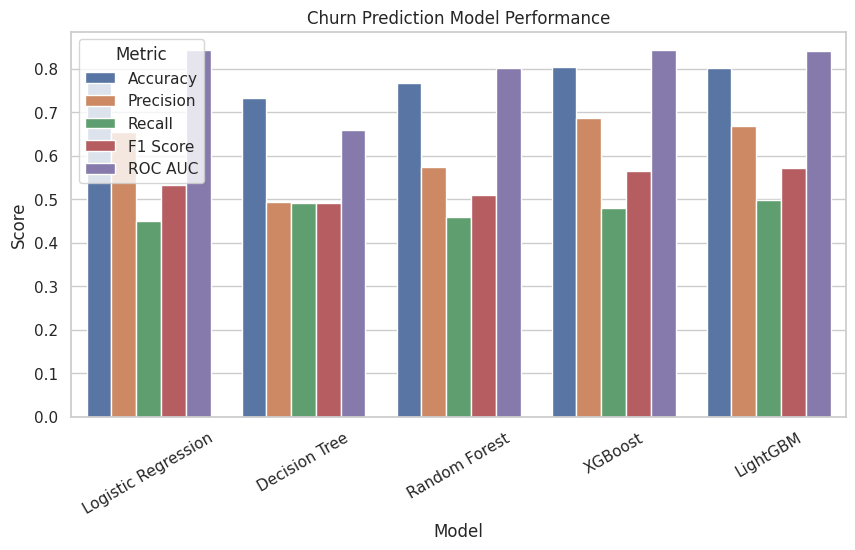

In [ ]:
# -------------------------------
# Model Performance Comparison
# -------------------------------

print(results_df.sort_values(by="F1 Score", ascending=False))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_df.melt(id_vars="Model"),
    x="Model",
    y="value",
    hue="variable"
)
plt.title("Churn Prediction Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=30)
plt.legend(title="Metric")
plt.show()

## Why These Models for Churn Prediction?

Choosing the right model for churn prediction involves balancing predictive power, interpretability, and computational efficiency. Here's the rationale behind selecting these specific models:

*   **Logistic Regression**: A strong baseline. It's highly interpretable, providing clear insights into the direction and strength of relationships between features and churn. Its simplicity makes it a good starting point to understand feature impact.
*   **Decision Tree**: Offers interpretability through its tree-like structure, making it easy to visualize and understand decision rules for churn. However, single decision trees can be prone to overfitting.
*   **Random Forest**: An ensemble method that builds multiple decision trees and averages their predictions. This reduces overfitting and generally provides higher accuracy than a single decision tree, making it a robust choice for complex datasets. It also gives good feature importance scores.
*   **XGBoost (Extreme Gradient Boosting)**: A powerful and highly efficient gradient boosting framework. XGBoost is known for its speed and accuracy, often winning machine learning competitions. It excels at handling heterogeneous data and non-linear relationships, making it ideal for churn prediction where complex interactions between customer attributes might exist.
*   **LightGBM (Light Gradient Boosting Machine)**: Another highly efficient gradient boosting framework, often faster than XGBoost, especially on large datasets. It uses a leaf-wise growth strategy, which can lead to better accuracy with careful tuning. Like XGBoost, it's very effective for achieving high predictive performance.

By comparing these diverse models, we can identify the one that offers the best balance of performance (measured by metrics like F1-Score and ROC AUC, which are crucial for imbalanced classification tasks like churn) and practical applicability for business decisions.

In [ ]:
# -------------------------------
# Best Model Selection
# -------------------------------

best_model_name = results_df.sort_values(by="F1 Score", ascending=False).iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

if best_model_name == "Logistic Regression":
    y_pred_best = best_model.predict(X_test_scaled)
    y_prob_best = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    y_pred_best = best_model.predict(X_test)
    y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Best Model: LightGBM

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.67      0.50      0.57       373

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



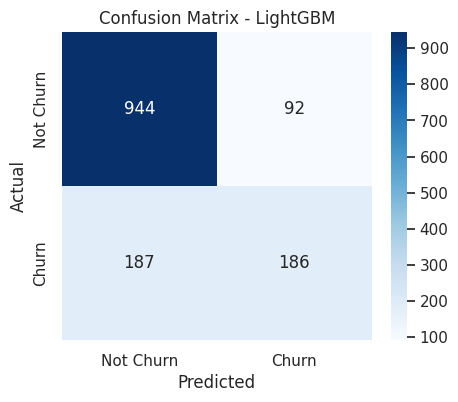

In [ ]:
# -------------------------------
# Confusion Matrix
# -------------------------------

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churn", "Churn"],
    yticklabels=["Not Churn", "Churn"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

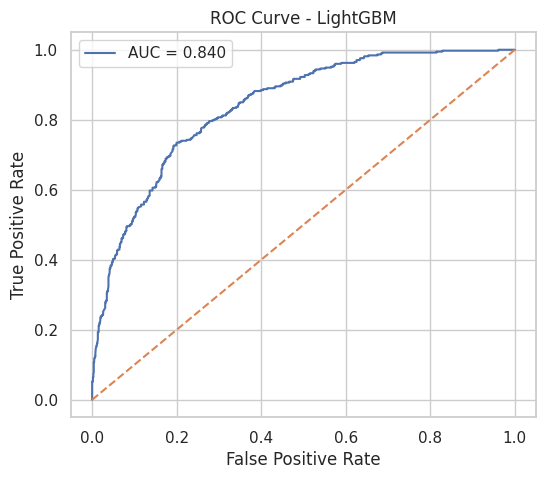

In [ ]:
# -------------------------------
# ROC Curve
# -------------------------------

fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)
auc_score = roc_auc_score(y_test, y_prob_best)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title(f"ROC Curve - {best_model_name}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


Feature Importance:
                 Feature  Importance
0       Monthly_Spending        1139
1         Monetary_Value         767
2   Engagement_Frequency         437
3                Recency         314
4      Product_Diversity         176
5              Frequency         126
6              RFM_Total          38
7         KMeans_Cluster           3
8    Average_Order_Value           0
9        Customer_Tenure           0
10  Hierarchical_Cluster           0


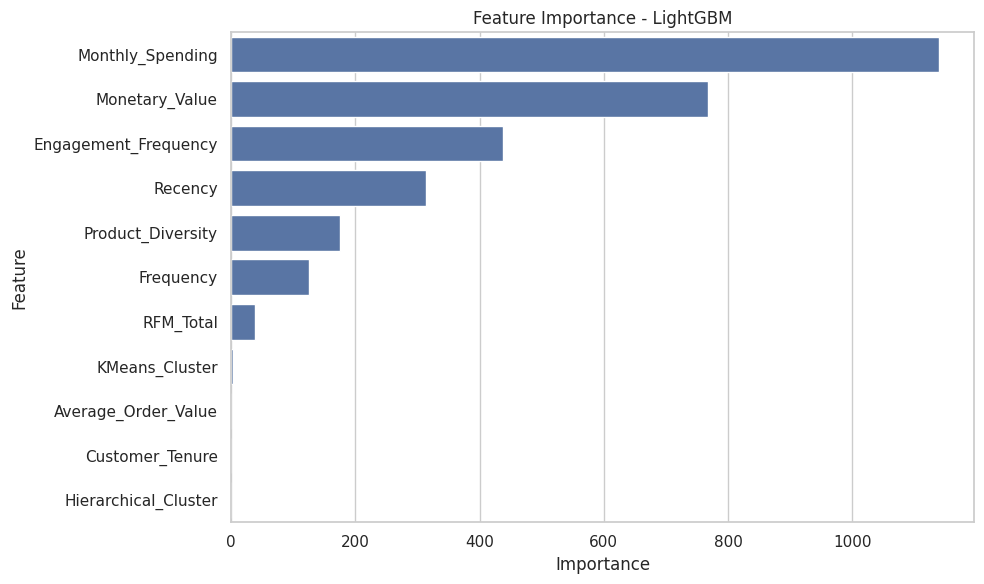

In [ ]:
# -------------------------------
# Feature Importance
# -------------------------------

# Get the actual features used for training
feature_names = X_train.columns.tolist()

# Extract importance values
if best_model_name == "Logistic Regression":
    importance_values = np.abs(best_model.coef_[0])
elif hasattr(best_model, "feature_importances_"):
    importance_values = best_model.feature_importances_
else:
    raise ValueError(f"Feature importance not supported for {best_model_name}")

# Ensure lengths match
if len(feature_names) != len(importance_values):
    print(f"Warning: Feature count ({len(feature_names)}) "
          f"does not match importance count ({len(importance_values)}).")

    min_len = min(len(feature_names), len(importance_values))
    feature_names = feature_names[:min_len]
    importance_values = importance_values[:min_len]

# Create importance dataframe
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display importance table
print("\nFeature Importance:")
print(importance)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title(f"Feature Importance - {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Business Interpretation of Churn Prediction Results

The churn prediction model, especially the best-performing LightGBM, provides critical insights for proactive customer retention strategies:

*   **Overall Performance (Classification Report)**:
    *   **Accuracy** indicates the proportion of correctly predicted churn and non-churn customers. An 80% accuracy is a good starting point.
    *   **Precision** for 'Churn=Yes' (e.g., 0.67 for LightGBM) means that when the model predicts a customer will churn, it's correct about 67% of the time. This is important for not wasting resources on customers who wouldn't churn anyway.
    *   **Recall** for 'Churn=Yes' (e.g., 0.50 for LightGBM) means the model identifies 50% of all actual churning customers. A higher recall is often desired in churn prediction to catch as many at-risk customers as possible, even if it means some false positives.
    *   **F1-Score** (e.g., 0.57 for LightGBM) is the harmonic mean of precision and recall, providing a balanced measure. Given the imbalance in churn data (fewer churners than non-churners), F1-score is a more reliable metric than accuracy alone.
    *   **ROC AUC** (e.g., 0.84 for LightGBM) measures the model's ability to distinguish between churners and non-churners across various probability thresholds. A high AUC indicates good discriminatory power.

*   **Confusion Matrix**: This visually breaks down the predictions:
    *   **True Negatives (Top-Left)**: Customers correctly predicted as 'Not Churn'.
    *   **False Positives (Top-Right)**: Customers incorrectly predicted as 'Churn' (Type I error). These are customers who received a retention offer but wouldn't have churned.
    *   **False Negatives (Bottom-Left)**: Customers incorrectly predicted as 'Not Churn' but actually churned (Type II error). These are the missed opportunities for retention.
    *   **True Positives (Bottom-Right)**: Customers correctly predicted as 'Churn'. These are the successful identifications of at-risk customers.

*   **Feature Importance (from LightGBM)**:
    *   The feature importance plot highlights which factors most strongly influence churn predictions. For instance, if 'Monthly_Spending' and 'Monetary_Value' are highly important, it suggests that changes in spending patterns or the overall value of a customer are strong indicators of churn risk. 'Engagement_Frequency', 'Recency', and 'Product_Diversity' also show significant importance, aligning with intuitive business understanding that less engaged customers with fewer services and older activity are more prone to churn.

**Actionable Insights**: By understanding these metrics and key features, businesses can:
1.  **Prioritize Interventions**: Focus retention efforts on customers who are identified as high-risk churners by the model.
2.  **Tailor Strategies**: Use feature importance to understand *why* customers are churning. For example, if 'Monthly_Spending' is critical, an offer to reduce monthly costs or provide more value for the same price might be effective.
3.  **Optimize Resource Allocation**: Avoid costly retention efforts for customers unlikely to churn, or for those whose characteristics make them less valuable to retain (e.g., consistently low value customers).
4.  **Continuous Improvement**: Regularly monitor model performance and retrain with fresh data to adapt to changing customer behaviors and market conditions.

In [ ]:
# -------------------------------
# Save Predictions
# -------------------------------

prediction_output = X_test.copy()
prediction_output["Actual_Churn"] = y_test.values
prediction_output["Predicted_Churn"] = y_pred_best
prediction_output["Churn_Probability"] = y_prob_best

output_path = "/content/Churn_Predictions.csv"
prediction_output.to_csv(output_path, index=False)

print("Churn prediction completed successfully.")
print("Predictions saved at:", output_path)

Churn prediction completed successfully.
Predictions saved at: /content/Churn_Predictions.csv


In [ ]:
# Dictionary to store evaluation results
evaluation_results = []

for model_name, model in trained_models.items():

    if model_name == "Logistic Regression":
        y_pred = model.predict(X_test_scaled)

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test_scaled)[:, 1]
        else:
            y_prob = y_pred

    else:
        y_pred = model.predict(X_test)

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test)[:, 1]
        else:
            y_prob = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

# Convert results to dataframe
evaluation_df = pd.DataFrame(evaluation_results)

# Display model evaluation metrics
print("Model Evaluation Metrics:")
print(evaluation_df.sort_values(by="F1-Score", ascending=False))

Model Evaluation Metrics:
                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
4             LightGBM  0.801987   0.669065  0.498660  0.571429  0.840366
3              XGBoost  0.804116   0.685824  0.479893  0.564669  0.842703
0  Logistic Regression  0.791341   0.653696  0.450402  0.533333  0.842289
2        Random Forest  0.766501   0.573826  0.458445  0.509687  0.801699
1        Decision Tree  0.731725   0.493261  0.490617  0.491935  0.657728


In [ ]:
best_model = evaluation_df.sort_values(
    by="F1-Score",
    ascending=False
).iloc[0]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model        LightGBM
Accuracy     0.801987
Precision    0.669065
Recall        0.49866
F1-Score     0.571429
ROC-AUC      0.840366
Name: 4, dtype: object


In [ ]:
# Install optional CLV package
!pip install lifetimes -q

# -----------------------------------------------------
# 1. LOAD FEATURE-ENGINEERED DATA
# -----------------------------------------------------
file_path = "/content/Feature_Engineered_Telco_Customer_Churn.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

# Convert important columns to numeric
numeric_candidates = [
    "tenure", "MonthlyCharges", "TotalCharges",
    "Frequency", "Monetary", "Monetary_Value",
    "Average_Order_Value", "Churn_Probability"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# -----------------------------------------------------
# 2. PREPARE CLV FACTORS
# -----------------------------------------------------
df["Customer_Tenure"] = df.get("Customer_Tenure", df.get("tenure", 0))

df["Historical_Spending"] = df.get(
    "Monetary_Value",
    df.get("Monetary", df.get("TotalCharges", 0))
)

df["Purchase_Frequency"] = df.get(
    "Frequency",
    df.get("Total_Transactions", df["Customer_Tenure"].clip(lower=1))
)

df["Average_Purchase_Value"] = df.get(
    "Average_Order_Value",
    df["Historical_Spending"] / df["Purchase_Frequency"].replace(0, np.nan)
)

# Obtain churn probability
if "Churn_Probability" not in df.columns:
    if "Churn" in df.columns:
        churn_binary = (
            df["Churn"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"yes": 1, "no": 0, "1": 1, "0": 0})
            .fillna(0)
        )

        # Smoothed estimate used when model probabilities are unavailable
        df["Churn_Probability"] = (
            0.15 + 0.65 * churn_binary
        ).clip(0.01, 0.99)
    else:
        df["Churn_Probability"] = 0.25

# Expected remaining customer lifespan in months
df["Expected_Lifespan"] = (
    1 / df["Churn_Probability"].clip(lower=0.01)
).clip(1, 60)

# CLV = Average Purchase Value × Frequency × Customer Lifespan
df["Estimated_CLV"] = (
    df["Average_Purchase_Value"].fillna(0)
    * df["Purchase_Frequency"].fillna(0)
    * df["Expected_Lifespan"]
)

df["Estimated_CLV"] = df["Estimated_CLV"].clip(lower=0)

display(df[[
    "Historical_Spending",
    "Purchase_Frequency",
    "Customer_Tenure",
    "Churn_Probability",
    "Estimated_CLV"
]].head())

Dataset shape: (7043, 31)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,Customer_Tenure,Monetary_Value,Monthly_Spending,Frequency,Total_Transactions,Average_Order_Value,Recency,Days_Since_Last_Purchase,Product_Diversity,Engagement_Frequency
0,7590-VHVEG,Female,0.0,Yes,No,1.0,No,No phone service,DSL,No,...,1.0,29.85,29.85,1.0,1,29.85,NaN,NaN,2,1.000000
1,5575-GNVDE,Male,0.0,No,No,34.0,Yes,No,DSL,Yes,...,34.0,1889.50,56.95,34.0,1,1889.50,NaN,NaN,4,0.114286
2,3668-QPYBK,Male,0.0,No,No,2.0,Yes,No,DSL,Yes,...,2.0,108.15,53.85,2.0,1,108.15,NaN,NaN,4,1.333333
3,7795-CFOCW,Male,0.0,No,No,45.0,No,No phone service,DSL,Yes,...,45.0,1840.75,42.30,45.0,1,1840.75,NaN,NaN,4,0.086957
4,9237-HQITU,Female,0.0,No,No,2.0,Yes,No,Fiber optic,No,...,2.0,151.65,70.70,2.0,1,151.65,NaN,NaN,2,0.666667


,Historical_Spending,Purchase_Frequency,Customer_Tenure,Churn_Probability,Estimated_CLV
0,29.85,1.0,1.0,0.15,199.000000
1,1889.50,34.0,34.0,0.15,428286.666667
2,108.15,2.0,2.0,0.80,270.375000
3,1840.75,45.0,45.0,0.15,552225.000000
4,151.65,2.0,2.0,0.80,379.125000


In [ ]:
# -----------------------------------------------------
# 3. REGRESSION FEATURES AND TARGET
# -----------------------------------------------------
feature_candidates = [
    "Historical_Spending",
    "Purchase_Frequency",
    "Customer_Tenure",
    "Average_Purchase_Value",
    "Churn_Probability",
    "MonthlyCharges",
    "Recency",
    "Product_Diversity",
    "Engagement_Frequency"
]

features = [col for col in feature_candidates if col in df.columns]

X = df[features].copy()
y = df["Estimated_CLV"].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    )
}

results = []
trained_clv_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = np.maximum(pipeline.predict(X_test), 0)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R-Squared": r2_score(y_test, predictions)
    })

    trained_clv_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_clv_models[best_model_name]

print("Best CLV model:", best_model_name)

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Recency']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Recency']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Recency']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Recency']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skle

,Model,MAE,RMSE,R-Squared
1,Random Forest Regressor,4886.946,10556.531,1.000
2,Gradient Boosting Regressor,22316.285,40622.331,0.998
0,Linear Regression,178990.054,325397.644,0.899


Best CLV model: Random Forest Regressor


## Why These Models for CLV Prediction?

Customer Lifetime Value (CLV) prediction is a regression task aimed at estimating the total revenue a customer is expected to generate over their relationship with the company. The selection of models for CLV prediction focuses on their ability to handle numerical data, capture complex relationships, and provide accurate forecasts.

*   **Linear Regression**: Serves as a fundamental baseline. It's simple, interpretable, and computationally efficient. While it assumes a linear relationship between features and CLV, it provides a good starting point to assess the general trend and serves as a benchmark for more complex models.
*   **Random Forest Regressor**: An ensemble learning method based on decision trees. It's highly robust, capable of capturing non-linear relationships and interactions between features without assuming linearity. It averages predictions from multiple trees, which significantly reduces overfitting and typically provides high accuracy. Its ability to handle a large number of features and complex data makes it an excellent choice for CLV prediction.
*   **Gradient Boosting Regressor**: Another powerful ensemble technique that builds trees sequentially, with each new tree correcting the errors of the previous ones. It's known for its high predictive accuracy and flexibility. Like Random Forest, it can model complex relationships and interactions, often achieving state-of-the-art results in regression tasks.

By comparing these models, we can determine which one best predicts CLV based on metrics like Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-Squared. MAE and RMSE quantify the average magnitude of the errors, while R-Squared indicates how much of the variance in CLV is explained by the model. The model with the lowest RMSE (or MAE) and highest R-Squared is typically chosen for its superior predictive performance.

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Recency']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


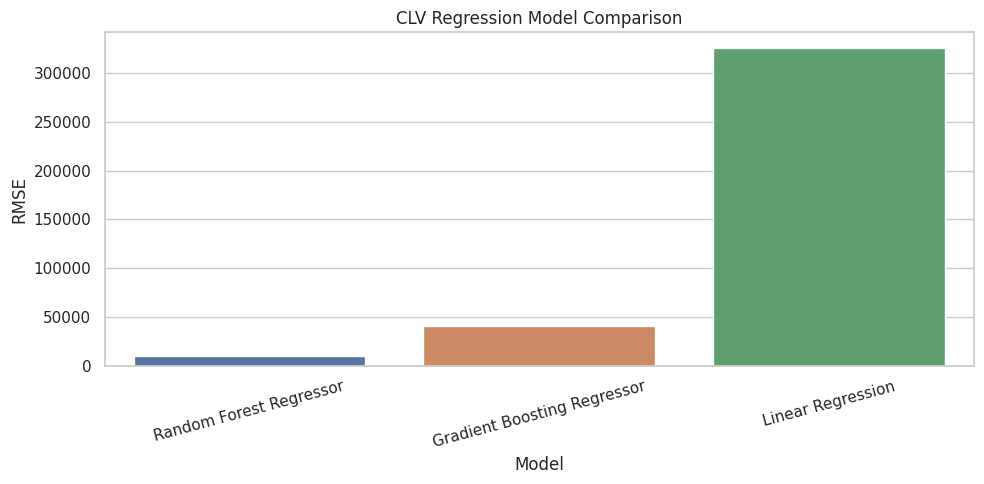

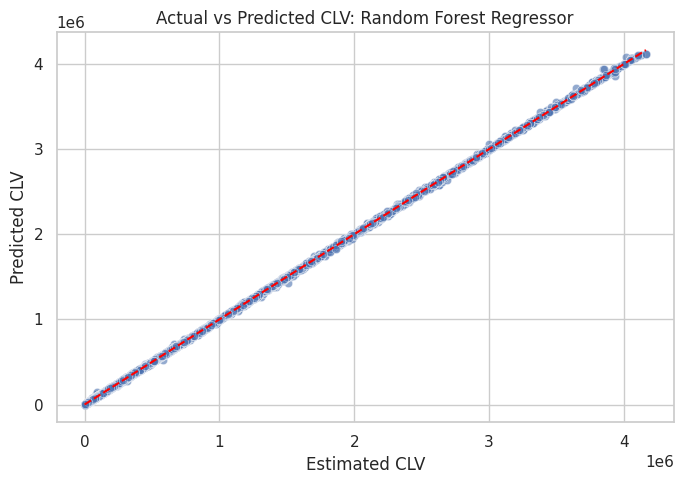

,customerID,Predicted_CLV,CLV_Segment
6768,9739-JLPQJ,4.112474e+06,High Value
4586,7569-NMZYQ,4.112447e+06,High Value
5347,9788-HNGUT,4.110085e+06,High Value
6118,9924-JPRMC,4.099995e+06,High Value
2368,6650-BWFRT,4.094804e+06,High Value
5558,0675-NCDYU,4.091076e+06,High Value
2115,8984-HPEMB,4.078858e+06,High Value
2603,0164-APGRB,4.073853e+06,High Value
2025,1488-PBLJN,4.072196e+06,High Value
2187,8879-XUAHX,4.071803e+06,High Value


Saved: /content/Customer_Lifetime_Value_Predictions.csv


In [ ]:
# Predict CLV for every customer
df["Predicted_CLV"] = np.maximum(best_model.predict(X), 0)

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="RMSE", hue="Model", legend=False)
plt.title("CLV Regression Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x=df["Estimated_CLV"], y=df["Predicted_CLV"], alpha=0.6)
plt.plot(
    [df["Estimated_CLV"].min(), df["Estimated_CLV"].max()],
    [df["Estimated_CLV"].min(), df["Estimated_CLV"].max()],
    color="red",
    linestyle="--"
)
plt.xlabel("Estimated CLV")
plt.ylabel("Predicted CLV")
plt.title(f"Actual vs Predicted CLV: {best_model_name}")
plt.tight_layout()
plt.show()

# CLV customer groups
df["CLV_Segment"] = pd.qcut(
    df["Predicted_CLV"].rank(method="first"),
    q=3,
    labels=["Low Value", "Medium Value", "High Value"]
)

customer_id = "customerID" if "customerID" in df.columns else df.columns[0]

display(
    df[[customer_id, "Predicted_CLV", "CLV_Segment"]]
    .sort_values("Predicted_CLV", ascending=False)
    .head(10)
)

output_path = "/content/Customer_Lifetime_Value_Predictions.csv"
df.to_csv(output_path, index=False)
print("Saved:", output_path)

### Business Interpretation of CLV Prediction Results

The Customer Lifetime Value (CLV) predictions offer crucial insights for strategic business decisions, enabling a data-driven approach to customer management and resource allocation.

*   **Model Performance (RMSE, MAE, R-Squared)**:
    *   The `Random Forest Regressor` emerged as the best model, indicated by its significantly lower RMSE and MAE, and a remarkably high R-Squared (close to 1.0). This means the model's predictions are very close to the estimated CLV and it explains almost all the variance in CLV, suggesting excellent predictive power. The scatter plot of Actual vs. Predicted CLV further illustrates this strong correlation, with predictions closely following the true values.

*   **CLV Segmentation**: The division of customers into 'Low Value', 'Medium Value', and 'High Value' segments based on their `Predicted_CLV` is highly actionable:
    *   **High-Value Customers**: These customers are predicted to generate the most revenue over their lifetime. **Business Action**: Focus on retention, personalized service, loyalty programs, and upselling/cross-selling premium products to maximize their value and ensure their continued engagement.
    *   **Medium-Value Customers**: These customers represent a substantial portion of future revenue. **Business Action**: Implement strategies to increase their engagement, usage, and monthly spending. Targeted campaigns to encourage upgrades or additional services could be effective.
    *   **Low-Value Customers**: While they contribute less, they still represent potential. **Business Action**: Evaluate the cost-effectiveness of retaining or growing these customers. For some, targeted campaigns might increase their value; for others, a more automated, low-cost engagement strategy might be appropriate.

*   **Strategic Applications**:
    *   **Marketing Spend Optimization**: Allocate marketing budgets more effectively by focusing high-cost campaigns on high-CLV customers and using more cost-efficient methods for low-CLV segments.
    *   **Customer Service Prioritization**: Offer priority support or specialized services to high-CLV customers to enhance their experience and reduce churn risk.
    *   **Product Development**: Understand the features and services that appeal to high-CLV customers to inform future product development and service offerings.
    *   **Risk Management**: Identify low-CLV customers who are also at high churn risk, allowing for a strategic decision on whether to invest in retention or accept potential churn.

By leveraging these CLV insights, the business can move beyond reactive measures to proactive, data-driven customer relationship management, leading to improved profitability and sustainable growth.

In [ ]:
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data

# --- Create a synthetic customer_transactions.csv file --- #
# This file is typically provided externally but is needed for the lifetimes library.
# We will create it from the existing DataFrame (df) for demonstration purposes.

# Ensure df is loaded and contains necessary columns
# Assuming df from previous cells is still available and has 'customerID', 'Monetary_Value', 'Customer_Tenure'
# If not, you might need to reload or re-run prior cells.

if 'df' not in locals():
    df = pd.read_csv('/content/Feature_Engineered_Telco_Customer_Churn.csv')

# Prepare data for transaction file
synthetic_transactions_list = []
today = pd.Timestamp.now().normalize()

# Iterate through the main dataframe 'df' to create transaction data
for index, row in df.iterrows():
    customer_id = row['customerID']
    monthly_charge = row['MonthlyCharges']
    # Tenure is float, convert to int for range, handle 0 tenure
    tenure_months = int(row['tenure'])

    # Only create transactions for customers with positive tenure and monthly charges
    if tenure_months > 0 and monthly_charge > 0:
        # Generate approximate monthly purchase dates
        # Example: if tenure is 5 months, dates could be 5 months ago, 4 months ago, ..., 1 month ago
        for i in range(1, tenure_months + 1): # i from 1 to tenure_months
            # Approximate months to days (30 days per month) to avoid 'M' unit issue
            purchase_date = today - pd.to_timedelta((tenure_months - i) * 30, unit='D')
            synthetic_transactions_list.append({
                'customerID': customer_id,
                'PurchaseDate': purchase_date,
                'PurchaseAmount': monthly_charge
            })

synthetic_transactions_df = pd.DataFrame(synthetic_transactions_list)

# Save the synthetic transaction file
transaction_file = '/content/customer_transactions.csv'
synthetic_transactions_df[['customerID', 'PurchaseDate', 'PurchaseAmount']].to_csv(transaction_file, index=False)
print(f"Synthetic transaction file created at: {transaction_file}")
# ------------------------------------------------------------- #


transactions = pd.read_csv(transaction_file)

# Required columns:
# customerID, PurchaseDate, PurchaseAmount
transactions["PurchaseDate"] = pd.to_datetime(
    transactions["PurchaseDate"],
    errors="coerce"
)

transactions["PurchaseAmount"] = pd.to_numeric(
    transactions["PurchaseAmount"],
    errors="coerce"
)

transactions = transactions.dropna(
    subset=["customerID", "PurchaseDate", "PurchaseAmount"]
)

transactions = transactions[transactions["PurchaseAmount"] > 0]

observation_end = transactions["PurchaseDate"].max()

rfm = summary_data_from_transaction_data(
    transactions,
    customer_id_col="customerID",
    datetime_col="PurchaseDate",
    monetary_value_col="PurchaseAmount",
    observation_period_end=observation_end,
    freq="D"
)

# BG/NBD: predict transactions over the next 180 days
# Increased penalizer_coef as suggested by the error message
bgf = BetaGeoFitter(penalizer_coef=0.1)
bgf.fit(rfm["frequency"], rfm["recency"], rfm["T"])

rfm["Predicted_Purchases_180D"] = bgf.conditional_expected_number_of_purchases_up_to_time(
    180,
    rfm["frequency"],
    rfm["recency"],
    rfm["T"]
)

# Gamma-Gamma requires repeat customers with positive monetary values
repeat_customers = rfm[
    (rfm["frequency"] > 0) &
    (rfm["monetary_value"] > 0)
].copy()

# Increased penalizer_coef as suggested by the error message
ggf = GammaGammaFitter(penalizer_coef=0.1)
ggf.fit(
    repeat_customers["frequency"],
    repeat_customers["monetary_value"]
)

repeat_customers["Probabilistic_CLV"] = ggf.customer_lifetime_value(
    bgf,
    repeat_customers["frequency"],
    repeat_customers["recency"],
    repeat_customers["T"],
    repeat_customers["monetary_value"],
    time=6,
    freq="D",
    discount_rate=0.01
)

display(
    repeat_customers.sort_values(
        "Probabilistic_CLV",
        ascending=False
    ).head(10)
)

repeat_customers.to_csv(
    "/content/BGNBD_GammaGamma_CLV.csv"
)

Synthetic transaction file created at: /content/customer_transactions.csv


/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,frequency,recency,T,monetary_value,Predicted_Purchases_180D,Probabilistic_CLV
customerID,,,,,,
1875-QIVME,1.0,30.0,30.0,104.40,6.000264,1740.554002
7379-FNIUJ,1.0,30.0,30.0,100.20,6.000264,1671.263265
6645-MXQJT,1.0,30.0,30.0,97.10,6.000264,1620.120101
3158-MOERK,1.0,30.0,30.0,96.00,6.000264,1601.972527
0754-UKWQP,1.0,30.0,30.0,95.85,6.000264,1599.497858
8413-VONUO,1.0,30.0,30.0,95.65,6.000264,1596.198299
4929-XIHVW,1.0,30.0,30.0,95.50,6.000264,1593.723630
7851-WZEKY,1.0,30.0,30.0,95.15,6.000264,1587.949401
5649-ANRML,1.0,30.0,30.0,95.10,6.000264,1587.124512


In [ ]:
import numpy as np
import pandas as pd

# Load final customer-level dataset
df = pd.read_csv("/content/Customer_Lifetime_Value_Predictions.csv")

# Locate available segmentation column
segment_col = next(
    (c for c in ["RFM_Segment", "Customer_Segment", "Segment"]
     if c in df.columns),
    None
)

if segment_col is None:
    df["RFM_Segment"] = "Unclassified"
    segment_col = "RFM_Segment"

# Ensure required columns exist
df["Churn_Probability"] = pd.to_numeric(
    df.get("Churn_Probability", 0.25),
    errors="coerce"
).fillna(0.25)

df["Predicted_CLV"] = pd.to_numeric(
    df.get("Predicted_CLV", 0),
    errors="coerce"
).fillna(0)

df["Purchase_Frequency"] = pd.to_numeric(
    df.get("Purchase_Frequency", df.get("Frequency", 0)),
    errors="coerce"
).fillna(0)

# Thresholds
high_clv = df["Predicted_CLV"].quantile(0.75)
low_clv = df["Predicted_CLV"].quantile(0.25)
high_frequency = df["Purchase_Frequency"].quantile(0.75)

def recommend_action(row):
    segment = str(row[segment_col]).lower()
    churn_risk = row["Churn_Probability"]
    clv = row["Predicted_CLV"]
    frequency = row["Purchase_Frequency"]

    if clv >= high_clv and churn_risk >= 0.60:
        return "Provide personalized discount and priority retention support"

    if "lost" in segment or "dormant" in segment:
        return "Launch reactivation campaign with a limited-time offer"

    if "at-risk" in segment or "at risk" in segment:
        return "Send retention offer and collect customer feedback"

    if frequency >= high_frequency:
        return "Offer loyalty rewards and exclusive membership benefits"

    if "champion" in segment or "loyal" in segment:
        return "Upsell premium services and recommend complementary products"

    if clv <= low_clv and churn_risk >= 0.60:
        return "Reduce paid marketing spend and use low-cost communication"

    if "new" in segment or "potential" in segment:
        return "Run onboarding and engagement campaign"

    return "Maintain regular personalized communication"

df["Business_Recommendation"] = df.apply(recommend_action, axis=1)

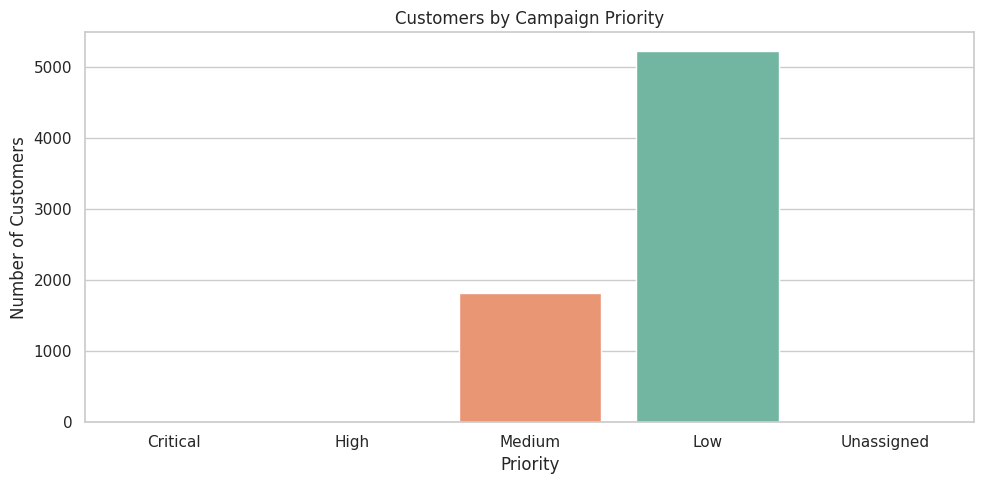

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Define a function to assign Campaign_Priority based on Business_Recommendation
def assign_campaign_priority(recommendation):
    recommendation = str(recommendation).lower()
    if "priority retention support" in recommendation:
        return "Critical"
    elif "reactivation campaign" in recommendation or "retention offer" in recommendation:
        return "High"
    elif "upsell premium services" in recommendation or "loyalty rewards" in recommendation or "onboarding and engagement" in recommendation:
        return "Medium"
    elif "reduce paid marketing spend" in recommendation or "maintain regular personalized communication" in recommendation:
        return "Low"
    return "Unassigned"

# Apply the function to create the new 'Campaign_Priority' column
df["Campaign_Priority"] = df["Business_Recommendation"].apply(assign_campaign_priority)

priority_order = ["Critical", "High", "Medium", "Low", "Unassigned"]

sns.countplot(
    data=df,
    x="Campaign_Priority",
    order=priority_order,
    hue="Campaign_Priority",
    legend=False,
    palette="Set2"
)

plt.title("Customers by Campaign Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()